In [1]:
import requests
from bs4 import BeautifulSoup
import re
import numpy as np
import pandas as pd
import time

headers ={
    "user-agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/150.0.0.0 Safari/537.36"
} 

base_url = "https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&p%5B%5D=facets.price_range.from%3D10000&p%5B%5D=facets.price_range.to%3DMax&page={}"

Title = []
Rating = []
Rating_review = []
RAM = []
ROM = []
Display = []
Battery = []
Price = []

# Scrape multiple pages
for page in range(1, 25):

    print("Scraping page:", page)

    url = base_url.format(page)

    res = requests.get(url, headers=headers)

    soup = BeautifulSoup(res.text, "html.parser")

    products = soup.find_all("div", class_="jIjQ8S")

    print("Products found:", len(products))

    for i in products:

        text = i.get_text(" ", strip=True)

        # Title
        title = i.find("div", class_="RG5Slk")
        if title:
            Title.append(title.get_text(strip=True))
        else:
            Title.append(np.nan)

        # Rating
        ra = i.find("div", class_="MKiFS6")
        if ra:
            Rating.append(ra.get_text(strip=True))
        else:
            Rating.append(np.nan)

        # Rating & Reviews
        review = i.find("span", class_="PvbNMB")
        if review:
            Rating_review.append(review.get_text(strip=True))
        else:
            Rating_review.append(np.nan)

        # RAM
        ram = re.findall(r"(\d+)\sGB\sRAM", text)
        if ram:
            RAM.append(ram[0])
        else:
            RAM.append(np.nan)

        # ROM
        rom = re.findall(r"(\d+)\sGB\sROM", text)
        if rom:
            ROM.append(rom[0])
        else:
            ROM.append(np.nan)

        # Display
        inch = re.findall(r"\((\d+\.\d+)\sinch\)", text)
        if inch:
            Display.append(inch[0])
        else:
            Display.append(np.nan)

        # Battery
        battery = re.findall(r"(\d+\s*mAh)", text)
        if battery:
            Battery.append(battery[0])
        else:
            Battery.append(np.nan)

        # Price
        price = re.findall(r"(₹\s*[\d,]+)", text)
        if price:
            Price.append(price[0])
        else:
            Price.append(np.nan)
    time.sleep(2)

    # Stop after collecting 500 to 600 rows
    if len(Title) >= 600:
        break
# Keep exactly 500 to 600 rows
Title = Title[:600]
Rating = Rating[:600]
Rating_review = Rating_review[:600]
RAM = RAM[:600]
ROM = ROM[:600]
Display = Display[:600]
Battery = Battery[:600]
Price = Price[:600]
# Create DataFrame
di = {
    "Title": Title,
    "Rating": Rating,
    "Rating_review": Rating_review,
    "RAM": RAM,
    "ROM": ROM,
    "Display": Display,
    "Battery": Battery,
    "Price": Price
}

Mobiles_data= pd.DataFrame(di)

print("Total rows:", len(Mobiles_data))

Mobiles_data.head()

Scraping page: 1
Products found: 24
Scraping page: 2
Products found: 24
Scraping page: 3
Products found: 24
Scraping page: 4
Products found: 24
Scraping page: 5
Products found: 24
Scraping page: 6
Products found: 24
Scraping page: 7
Products found: 24
Scraping page: 8
Products found: 24
Scraping page: 9
Products found: 24
Scraping page: 10
Products found: 24
Scraping page: 11
Products found: 24
Scraping page: 12
Products found: 24
Scraping page: 13
Products found: 24
Scraping page: 14
Products found: 24
Scraping page: 15
Products found: 24
Scraping page: 16
Products found: 24
Scraping page: 17
Products found: 24
Scraping page: 18
Products found: 24
Scraping page: 19
Products found: 24
Scraping page: 20
Products found: 24
Scraping page: 21
Products found: 24
Scraping page: 22
Products found: 24
Scraping page: 23
Products found: 24
Scraping page: 24
Products found: 24
Total rows: 576


,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
0,"Ai+ Nova 2 5G (Blue, 128 GB)",4,"5,953 Ratings&469 Reviews",6,128,6.745,6000 mAh,"₹14,999"
1,"Samsung Galaxy F07 (Green, 64 GB)",4.2,"10,788 Ratings&773 Reviews",4,64,6.7,5000 mAh,"₹11,999"
2,"REDMI A7 Pro 5G (Black, 64 GB)",3.9,"4,547 Ratings&398 Reviews",4,64,6.9,6300 mAh,"₹14,579"
3,"vivo T5 Lite 44W 5G (Twilight Shadow, 128 GB)",4.3,"3,442 Ratings&268 Reviews",6,128,6.74,6500 mAh,"₹22,999"
4,"BOLTT EVO (Midnight Black, 128 GB)",3.9,"1,593 Ratings&737 Reviews",6,128,6.79,6000 mAh,"₹11,499"


In [2]:
Mobiles_data.shape

(576, 8)

In [3]:
Mobiles_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 576 entries, 0 to 575
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Title          576 non-null    object
 1   Rating         576 non-null    object
 2   Rating_review  576 non-null    object
 3   RAM            554 non-null    object
 4   ROM            576 non-null    object
 5   Display        564 non-null    object
 6   Battery        554 non-null    object
 7   Price          575 non-null    object
dtypes: object(8)
memory usage: 36.1+ KB


In [4]:
# The missing values in the dataset were identified and handled appropriately to ensure data completeness and consistency
# The data types of the columns were converted from object to the appropriate data types for analysis.
# Special characters and unnecessary symbols were removed from the data to ensure consistency and enable proper analysis

In [5]:
Mobiles_data.isnull().sum()

Title             0
Rating            0
Rating_review     0
RAM              22
ROM               0
Display          12
Battery          22
Price             1
dtype: int64

In [6]:
Mobiles_data["RAM"]=Mobiles_data["RAM"].fillna(Mobiles_data["RAM"].mode()[0])

In [7]:
Mobiles_data["Display"]=Mobiles_data["Display"].fillna(Mobiles_data["Display"].mode()[0])

In [8]:
Mobiles_data["Battery"]=Mobiles_data["Battery"].fillna(Mobiles_data["Battery"].mode()[0])

In [24]:
Mobiles_data["Price"]=Mobiles_data["Price"].fillna(Mobiles_data["Price"].mode()[0])

In [25]:
Mobiles_data.isnull().sum()

Title            0
Rating           0
Rating_review    0
RAM              0
ROM              0
Display          0
Battery          0
Price            0
dtype: int64

In [10]:
Mobiles_data["Rating"]=Mobiles_data["Rating"].astype(float)

In [11]:
Mobiles_data["ROM"]=Mobiles_data["ROM"].astype(int)


In [12]:
Mobiles_data["RAM"]=Mobiles_data["RAM"].astype(int)

In [13]:
Mobiles_data["Display"]=Mobiles_data["Display"].astype(float)

In [14]:
Mobiles_data["Battery"]=Mobiles_data["Battery"].str.replace("mAh"," ",regex=False)

In [15]:
Mobiles_data["Battery"]=Mobiles_data["Battery"].astype(int)

In [16]:
Mobiles_data["Price"]=Mobiles_data["Price"].str.replace("₹"," ",regex=False)

In [17]:
Mobiles_data["Price"]=Mobiles_data["Price"].str.replace("₹"," ",regex=False)

In [21]:
Mobiles_data["Price"]=Mobiles_data["Price"].str.replace("," ," ",regex=False)

In [22]:
Mobiles_data["Price"]=Mobiles_data["Price"].str.replace(" ","",regex=False)

In [26]:
Mobiles_data["Price"]=Mobiles_data["Price"].astype(int)

In [27]:
Mobiles_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 576 entries, 0 to 575
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Title          576 non-null    object 
 1   Rating         576 non-null    float64
 2   Rating_review  576 non-null    object 
 3   RAM            576 non-null    int64  
 4   ROM            576 non-null    int64  
 5   Display        576 non-null    float64
 6   Battery        576 non-null    int64  
 7   Price          576 non-null    int64  
dtypes: float64(2), int64(4), object(2)
memory usage: 36.1+ KB


In [28]:
Mobiles_data[Mobiles_data.duplicated()]

,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
39,"LAVA Virat V1 5G (Sonar Gold, 64 GB)",4.1,"1,096 Ratings&202 Reviews",4,64,6.75,6000,13499
50,"Tecno Spark Go 3 (Ink Black, 64 GB)",4.1,218 Ratings&15 Reviews,4,64,6.74,5000,12499
76,"REDMI 15 5G (Sandy Purple, 128 GB)",4.3,"3,275 Ratings&248 Reviews",6,128,6.90,7000,22499
89,"Infinix Note edge (Silk Green, 128 GB)",4.3,510 Ratings&87 Reviews,8,128,6.78,6500,23999
98,"POCO C81x (Ice Blue, 64 GB)",3.9,657 Ratings&39 Reviews,3,64,6.88,5200,11999
...,...,...,...,...,...,...,...,...
508,"Samsung Galaxy A06 5G (Light Green, 128 GB)",4.1,"4,999 Ratings&378 Reviews",4,128,6.70,5000,17462
552,"realme GT 8 Pro (Diary White, 512 GB)",4.6,113 Ratings&23 Reviews,16,512,6.79,7000,78999
553,"IQOO Z11 5G (Aurora Green, 128 GB)",4.9,11 Ratings&2 Reviews,8,128,6.83,7050,38470
554,"Apple iPhone 18 Pro (Glacier, 512 GB)",4.7,220 Ratings&29 Reviews,8,512,6.30,6000,189900


In [29]:
Mobiles_data.duplicated().sum()

np.int64(99)

In [33]:
Mobiles_data.drop_duplicates(inplace=True)

In [37]:
Mobiles_data.duplicated().sum()

np.int64(0)

In [38]:
Mobiles_data.shape

(477, 8)

In [39]:
Mobiles_data.describe()

,Rating,RAM,ROM,Display,Battery,Price
count,477.000000,477.000000,477.000000,477.000000,477.000000,477.000000
mean,4.290776,7.182390,178.716981,6.851629,6366.247379,35941.937107
std,0.216831,2.781667,109.698429,1.068648,1084.511510,31713.404832
min,3.700000,3.000000,64.000000,6.100000,3900.000000,10499.000000
25%,4.200000,4.000000,128.000000,6.700000,6000.000000,17999.000000
50%,4.300000,8.000000,128.000000,6.780000,6000.000000,26289.000000
75%,4.400000,8.000000,256.000000,6.800000,7000.000000,39999.000000
max,5.000000,16.000000,1024.000000,17.130000,10001.000000,204900.000000


In [40]:
Mobiles_data.nlargest(10, "Display")

,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
221,"Samsung Galaxy A07 5G (Light Violet, 128 GB)",4.3,88 Ratings&7 Reviews,6,128,17.13,6000,20999
314,"Samsung Galaxy A07 5G (Black, 128 GB)",3.9,122 Ratings&14 Reviews,4,128,17.13,6000,18999
357,"Samsung Galaxy A07 5G (Light Green, 128 GB)",4.3,88 Ratings&7 Reviews,6,128,17.13,6000,20390
358,"Samsung Galaxy A07 5G (Black, 128 GB)",4.3,88 Ratings&7 Reviews,6,128,17.13,6000,20778
409,"Samsung Galaxy A07 5G (Light Violet, 128 GB)",3.9,122 Ratings&14 Reviews,4,128,17.13,6000,17868
72,"POCO M8 Power 5G (Blaze Orange, 128 GB)",4.7,"1,529 Ratings&893 Reviews",6,128,6.99,8000,24999
542,"POCO M8 Power 5G (Black, 128 GB)",4.7,"1,529 Ratings&893 Reviews",6,128,6.99,8000,24999
2,"REDMI A7 Pro 5G (Black, 64 GB)",3.9,"4,547 Ratings&398 Reviews",4,64,6.90,6300,14579
14,"REDMI A7 Pro 5G (Mist Blue, 64 GB)",3.9,"4,547 Ratings&398 Reviews",4,64,6.90,6300,14599
23,"Ai+ Nova 2 Pro 5G (Blue, 128 GB)",4.0,"2,361 Ratings&274 Reviews",6,128,6.90,6000,17999


In [41]:
Mobiles_data.nlargest(10,"Battery")

,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
132,realme P4 Power 5G Charger in the Box (TransOr...,4.4,"8,621 Ratings&903 Reviews",8,256,6.8,10001,34999
347,"realme P4 Power 5G (TransSilver, 256 GB)",4.4,"1,876 Ratings&256 Reviews",12,256,6.8,10001,37999
352,"realme P4 Power 5G (TransSilver, 256 GB)",4.4,"8,621 Ratings&903 Reviews",8,256,6.8,10001,34999
364,"realme P4 Power 5G (TransSilver, 128 GB)",4.4,"8,621 Ratings&903 Reviews",8,128,6.8,10001,32999
366,"realme P4 Power 5G (TransBlue, 128 GB)",4.4,"8,621 Ratings&903 Reviews",8,128,6.8,10001,32999
407,"realme P4 Power 5G (TransBlue, 256 GB)",4.4,"8,621 Ratings&903 Reviews",8,256,6.8,10001,34999
422,"realme Narzo Power 5G (Titan Silver, 256 GB)",4.3,107 Ratings&10 Reviews,8,256,6.8,10001,33497
423,"realme Narzo Power 5G (Titan Silver, 128 GB)",4.3,107 Ratings&10 Reviews,8,128,6.8,10001,32899
496,"realme Narzo Power 5G (Titan Blue, 128 GB)",4.3,107 Ratings&10 Reviews,8,128,6.8,10001,28908
517,"realme Narzo Power 5G (Titan Blue, 256 GB)",4.3,107 Ratings&10 Reviews,8,256,6.8,10001,36306


In [42]:
Mobiles_data.nlargest(10,"Price")

,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
382,"Apple iPhone 18 Pro max (Glacier, 512 GB)",4.8,87 Ratings&17 Reviews,8,512,6.9,6000,204900
551,"Apple iPhone 18 Pro max (Burgundy, 512 GB)",4.8,87 Ratings&17 Reviews,8,512,6.9,6000,204900
324,"Samsung Galaxy S26 Ultra 5G (Cobalt Violet, 10...",5.0,5 Ratings&1 Reviews,16,1024,6.9,5000,189999
265,"Apple iPhone 18 Pro (Burgundy, 512 GB)",4.7,220 Ratings&29 Reviews,8,512,6.3,6000,189900
547,"Apple iPhone 18 Pro (Glacier, 512 GB)",4.7,220 Ratings&29 Reviews,8,512,6.3,6000,189900
125,"Samsung Galaxy Z Fold7 5G (Silver Shadow, 512 GB)",4.6,185 Ratings&11 Reviews,12,512,6.8,4400,186999
468,"Apple iPhone 18 Pro max (Black, 256 GB)",4.8,87 Ratings&17 Reviews,8,256,6.9,6000,179900
106,"Apple iPhone 18 Pro (Burgundy, 256 GB)",4.7,220 Ratings&29 Reviews,8,256,6.3,6000,164900
130,"Apple iPhone 18 Pro (Silver, 256 GB)",4.7,220 Ratings&29 Reviews,8,256,6.3,6000,164900
303,"Samsung Galaxy S26 Ultra 5G (Cobalt Violet, 51...",4.6,"1,367 Ratings&355 Reviews",12,512,6.9,5000,159999


In [44]:
Mobiles_data.duplicated().sum()

np.int64(0)

In [45]:
Q1 = Mobiles_data["Price"].quantile(0.25)
Q3 = Mobiles_data["Price"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [46]:
Mobiles_data[(Mobiles_data["Price"] < lower) | 
             (Mobiles_data["Price"] > upper)]

,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
106,"Apple iPhone 18 Pro (Burgundy, 256 GB)",4.7,220 Ratings&29 Reviews,8,256,6.300,6000,164900
125,"Samsung Galaxy Z Fold7 5G (Silver Shadow, 512 GB)",4.6,185 Ratings&11 Reviews,12,512,6.800,4400,186999
130,"Apple iPhone 18 Pro (Silver, 256 GB)",4.7,220 Ratings&29 Reviews,8,256,6.300,6000,164900
165,Samsung Galaxy S25 Ultra 5G (Titanium Silverbl...,4.6,"4,225 Ratings&451 Reviews",12,256,6.900,5000,95690
185,"Samsung S25 Ultra 5G (Titanium Gray, 256 GB)",4.6,967 Ratings&88 Reviews,12,256,6.900,5000,95390
189,"Samsung Galaxy Z Fold7 5G (Silver Shadow, 256 GB)",4.6,185 Ratings&11 Reviews,12,256,6.800,4400,154999
194,"Google Pixel 10 (Frost, 256 GB)",4.5,"3,711 Ratings&353 Reviews",12,256,6.300,4970,79999
231,"Apple iPhone 17 (White, 256 GB)",4.6,"28,217 Ratings&2,046 Reviews",8,256,6.300,6000,99900
239,"Apple iPhone 16 Plus (White, 128 GB)",4.6,"4,342 Ratings&294 Reviews",8,128,6.700,6000,79900
265,"Apple iPhone 18 Pro (Burgundy, 512 GB)",4.7,220 Ratings&29 Reviews,8,512,6.300,6000,189900


In [49]:
Q1=Mobiles_data["RAM"].quantile(0.25)
Q3=Mobiles_data["RAM"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
Mobiles_data[(Mobiles_data["RAM"]<lower)|(Mobiles_data["RAM"]>upper)]

,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
321,"IQOO 15 5G (Legend, 512 GB)",4.6,174 Ratings&26 Reviews,16,512,6.85,7000,88990
324,"Samsung Galaxy S26 Ultra 5G (Cobalt Violet, 10...",5.0,5 Ratings&1 Reviews,16,1024,6.90,5000,189999
451,"MOTOROLA Signature (PANTONE Carbon, 512 GB)",4.5,"1,270 Ratings&231 Reviews",16,512,6.80,5200,64999
549,"realme GT 8 Pro (Diary White, 512 GB)",4.6,113 Ratings&23 Reviews,16,512,6.79,7000,78999
569,REDMI Note 15 Pro+ 5G Special Edition Carbon B...,5.0,4 Ratings&1 Reviews,16,512,6.83,6500,49999


In [51]:
Q1=Mobiles_data["ROM"].quantile(0.25)
Q3=Mobiles_data["ROM"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
Mobiles_data[(Mobiles_data["ROM"]<lower)|(Mobiles_data["ROM"]>upper)]

,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
125,"Samsung Galaxy Z Fold7 5G (Silver Shadow, 512 GB)",4.6,185 Ratings&11 Reviews,12,512,6.80,4400,186999
208,"realme Gt 7 (Icesense Black, 512 GB)",4.5,"1,543 Ratings&198 Reviews",12,512,6.78,7000,52999
265,"Apple iPhone 18 Pro (Burgundy, 512 GB)",4.7,220 Ratings&29 Reviews,8,512,6.30,6000,189900
276,"MOTOROLA Edge 70 Fusion (Pantone ORIENT BLUE, ...",4.3,"6,858 Ratings&761 Reviews",12,512,6.80,7000,36999
287,"MOTOROLA Edge 70 Fusion (Pantone SILHOUETTE, 5...",4.3,"6,858 Ratings&761 Reviews",12,512,6.80,7000,36999
303,"Samsung Galaxy S26 Ultra 5G (Cobalt Violet, 51...",4.6,"1,367 Ratings&355 Reviews",12,512,6.90,5000,159999
304,"Samsung Galaxy S26 Ultra 5G (White, 512 GB)",4.6,"1,367 Ratings&355 Reviews",12,512,6.90,5000,159999
321,"IQOO 15 5G (Legend, 512 GB)",4.6,174 Ratings&26 Reviews,16,512,6.85,7000,88990
324,"Samsung Galaxy S26 Ultra 5G (Cobalt Violet, 10...",5.0,5 Ratings&1 Reviews,16,1024,6.90,5000,189999
336,"Samsung Galaxy S26 Ultra 5G (Sky Blue, 512 GB)",4.6,"1,367 Ratings&355 Reviews",12,512,6.90,5000,151497


In [52]:
Q1=Mobiles_data["Display"].quantile(0.25)
Q3=Mobiles_data["Display"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
Mobiles_data[(Mobiles_data["Display"]<lower)|(Mobiles_data["Display"]>upper)]

,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
72,"POCO M8 Power 5G (Blaze Orange, 128 GB)",4.7,"1,529 Ratings&893 Reviews",6,128,6.99,8000,24999
106,"Apple iPhone 18 Pro (Burgundy, 256 GB)",4.7,220 Ratings&29 Reviews,8,256,6.30,6000,164900
112,"Apple iPhone 15 (Blue, 256 GB)",4.6,"2,49,080 Ratings&9,816 Reviews",8,256,6.10,6000,69900
114,"Apple iPhone 15 (Black, 256 GB)",4.6,"2,49,080 Ratings&9,816 Reviews",8,256,6.10,6000,69900
130,"Apple iPhone 18 Pro (Silver, 256 GB)",4.7,220 Ratings&29 Reviews,8,256,6.30,6000,164900
158,"Samsung Galaxy S24 Exynos 5G (Amber Yellow, 25...",4.5,"6,859 Ratings&521 Reviews",8,256,6.20,4000,55999
194,"Google Pixel 10 (Frost, 256 GB)",4.5,"3,711 Ratings&353 Reviews",12,256,6.30,4970,79999
221,"Samsung Galaxy A07 5G (Light Violet, 128 GB)",4.3,88 Ratings&7 Reviews,6,128,17.13,6000,20999
231,"Apple iPhone 17 (White, 256 GB)",4.6,"28,217 Ratings&2,046 Reviews",8,256,6.30,6000,99900
265,"Apple iPhone 18 Pro (Burgundy, 512 GB)",4.7,220 Ratings&29 Reviews,8,512,6.30,6000,189900


In [53]:
Q1=Mobiles_data["Battery"].quantile(0.25)
Q3=Mobiles_data["Battery"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
Mobiles_data[(Mobiles_data["Battery"]<lower)|(Mobiles_data["Battery"]>upper)]

,Title,Rating,Rating_review,RAM,ROM,Display,Battery,Price
125,"Samsung Galaxy Z Fold7 5G (Silver Shadow, 512 GB)",4.6,185 Ratings&11 Reviews,12,512,6.800,4400,186999
132,realme P4 Power 5G Charger in the Box (TransOr...,4.4,"8,621 Ratings&903 Reviews",8,256,6.800,10001,34999
158,"Samsung Galaxy S24 Exynos 5G (Amber Yellow, 25...",4.5,"6,859 Ratings&521 Reviews",8,256,6.200,4000,55999
189,"Samsung Galaxy Z Fold7 5G (Silver Shadow, 256 GB)",4.6,185 Ratings&11 Reviews,12,256,6.800,4400,154999
201,"OnePlus Nord 6 (Pitch Black, 256 GB)",4.5,"2,559 Ratings&306 Reviews",8,256,6.780,9000,46800
202,"OnePlus Nord 6 (Fresh Mint, 256 GB)",4.5,"2,559 Ratings&306 Reviews",8,256,6.780,9000,46990
205,"OnePlus Nord 6 (Quick Silver, 256 GB)",4.5,"2,559 Ratings&306 Reviews",8,256,6.780,9000,46748
220,"OnePlus Nord 6 (Fresh Mint, 256 GB)",4.5,269 Ratings&31 Reviews,12,256,6.780,9000,54900
320,"IQOO Z3 5G (Ace Black, 256 GB)",4.3,187 Ratings&11 Reviews,8,256,6.580,4400,26990
325,"POCO X8 Power 5G (Black, 256 GB)",4.3,263 Ratings&68 Reviews,8,256,6.830,10000,38999


In [54]:
#Univariate Analysis

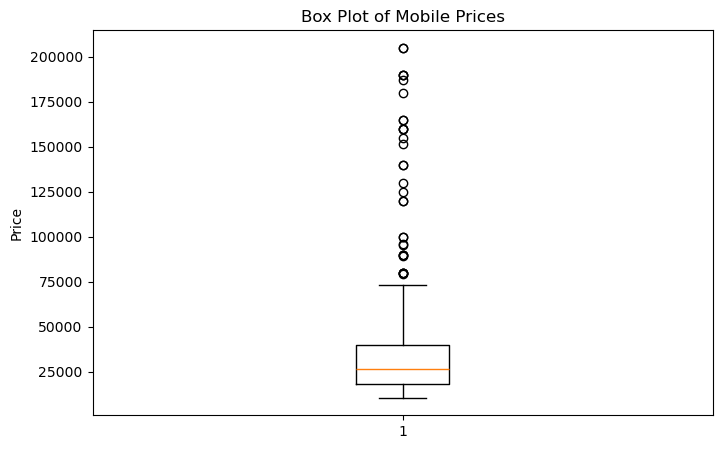

In [74]:
# Visualize Price distribution and identify potential outliers
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.boxplot(Mobiles_data["Price"])
plt.ylabel("Price")
plt.title("Box Plot of Mobile Prices")
plt.show()

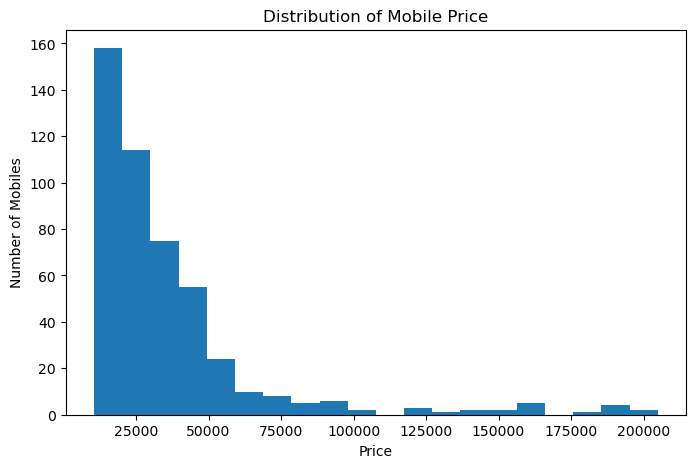

In [72]:
plt.figure(figsize=(8,5))
plt.hist(Mobiles_data["Price"],bins=20)
plt.xlabel("Price")
plt.ylabel("Number of Mobiles")
plt.title("Distribution of Mobile Price")
plt.show()

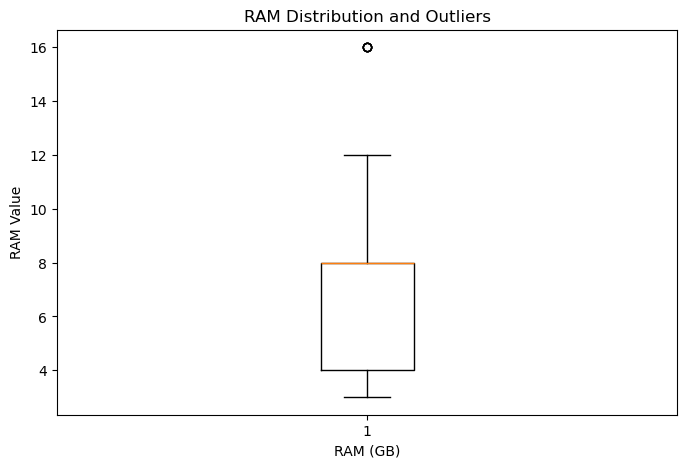

In [81]:
# Visualize RAM distribution and identify potential outliers
plt.figure(figsize=(8, 5))
plt.boxplot(Mobiles_data["RAM"])
plt.xlabel("RAM (GB)")
plt.ylabel("RAM Value")
plt.title("RAM Distribution and Outliers")
plt.show()

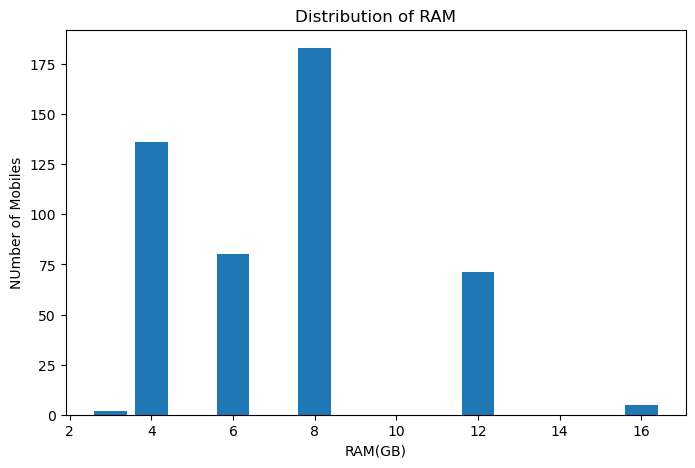

In [84]:
# Analyze the distribution of RAM across mobile devices
ram_counts=Mobiles_data["RAM"].value_counts().sort_index()
plt.figure(figsize=(8,5))
plt.bar(ram_counts.index,ram_counts)
plt.title("Distribution of RAM")
plt.xlabel("RAM(GB)")
plt.ylabel("NUmber of Mobiles")
plt.show()

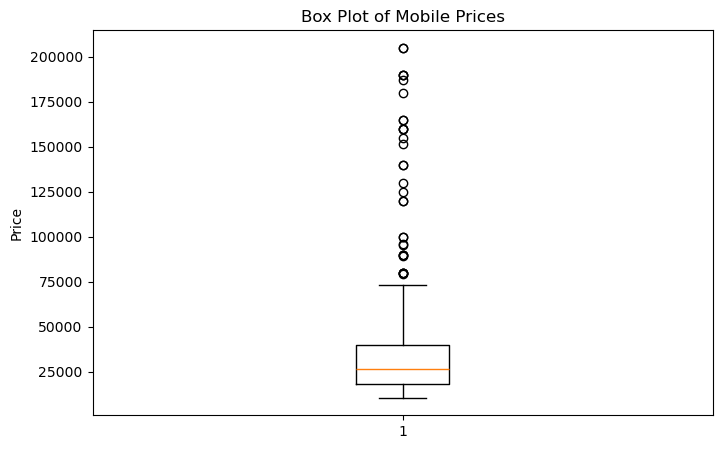

In [88]:
# Visualize Rom distribution and identify potential outliers
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.boxplot(Mobiles_data["Price"])
plt.ylabel("Price")
plt.title("Box Plot of Mobile Prices")
plt.show()

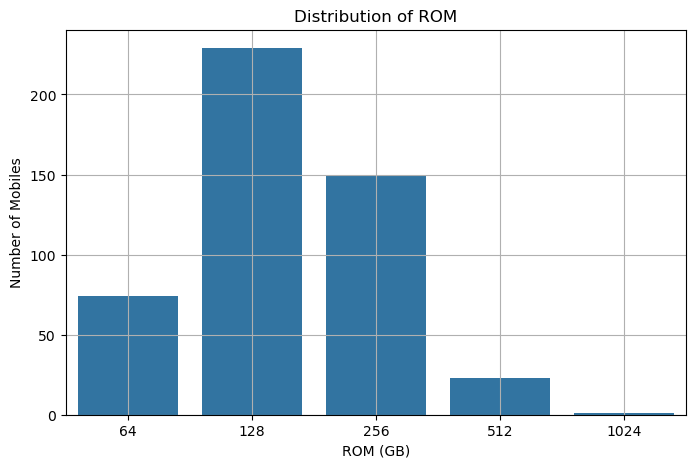

In [94]:
# Analyze the distribution of ROM across mobile devices
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.countplot(x="ROM",data=Mobiles_data)
plt.grid()
plt.title("Distribution of ROM")
plt.xlabel("ROM (GB)")
plt.ylabel("Number of Mobiles")
plt.show()

In [89]:
 # Bivariate Analysis

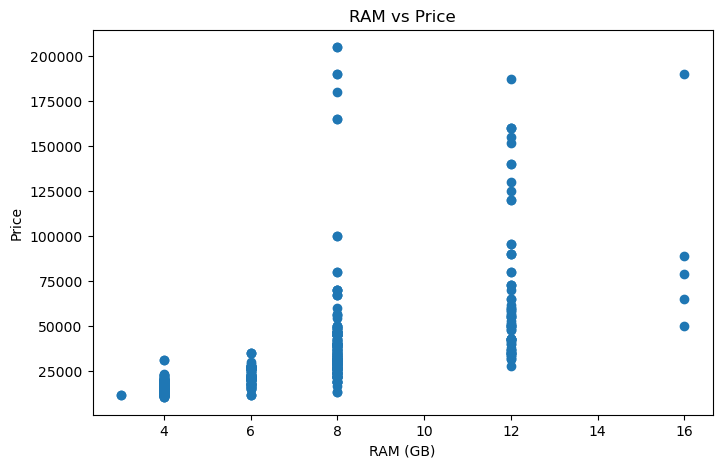

In [98]:
# Analyze the relationship between RAM and mobile price
plt.figure(figsize=(8, 5))
plt.scatter(Mobiles_data["RAM"], Mobiles_data["Price"])
plt.title("RAM vs Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Price")
plt.show()

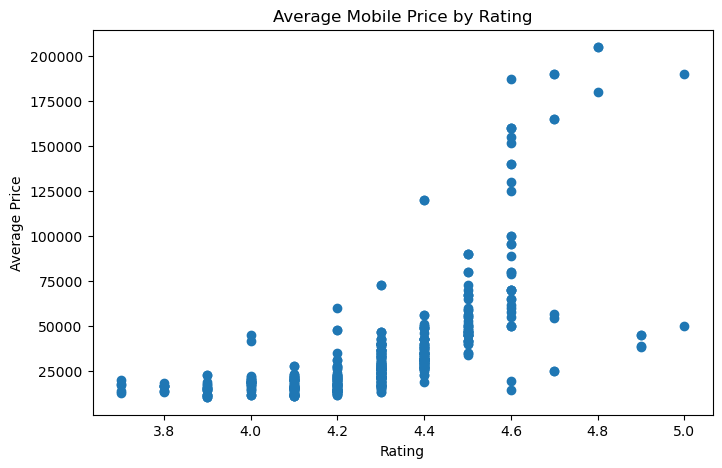

In [109]:
# Analyze average mobile price by rating
plt.figure(figsize=(8, 5))
plt.scatter(Mobiles_data["Rating"] ,Mobiles_data["Price"])
plt.title("Average Mobile Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price")
plt.show()

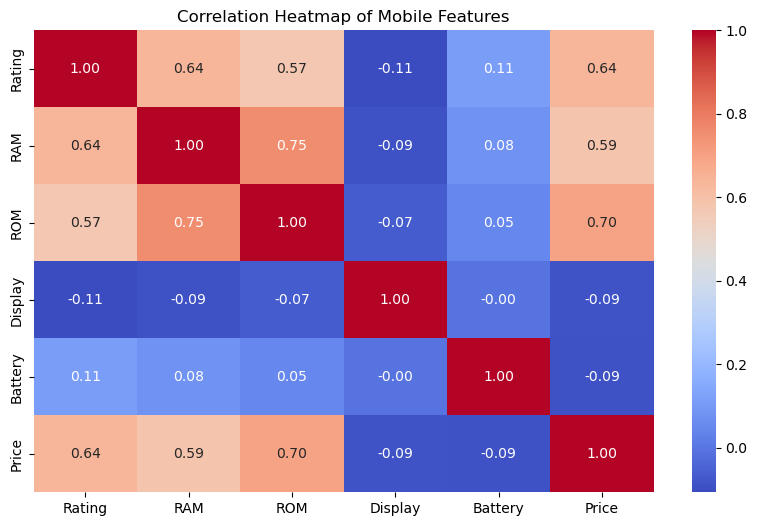

In [119]:
# Multivariate Analysis
# Analyze correlations among numerical features
plt.figure(figsize=(10, 6))

Mobile_correlation = Mobiles_data.corr(numeric_only=True)
sns.heatmap(Mobile_correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Mobile Features")
plt.show()

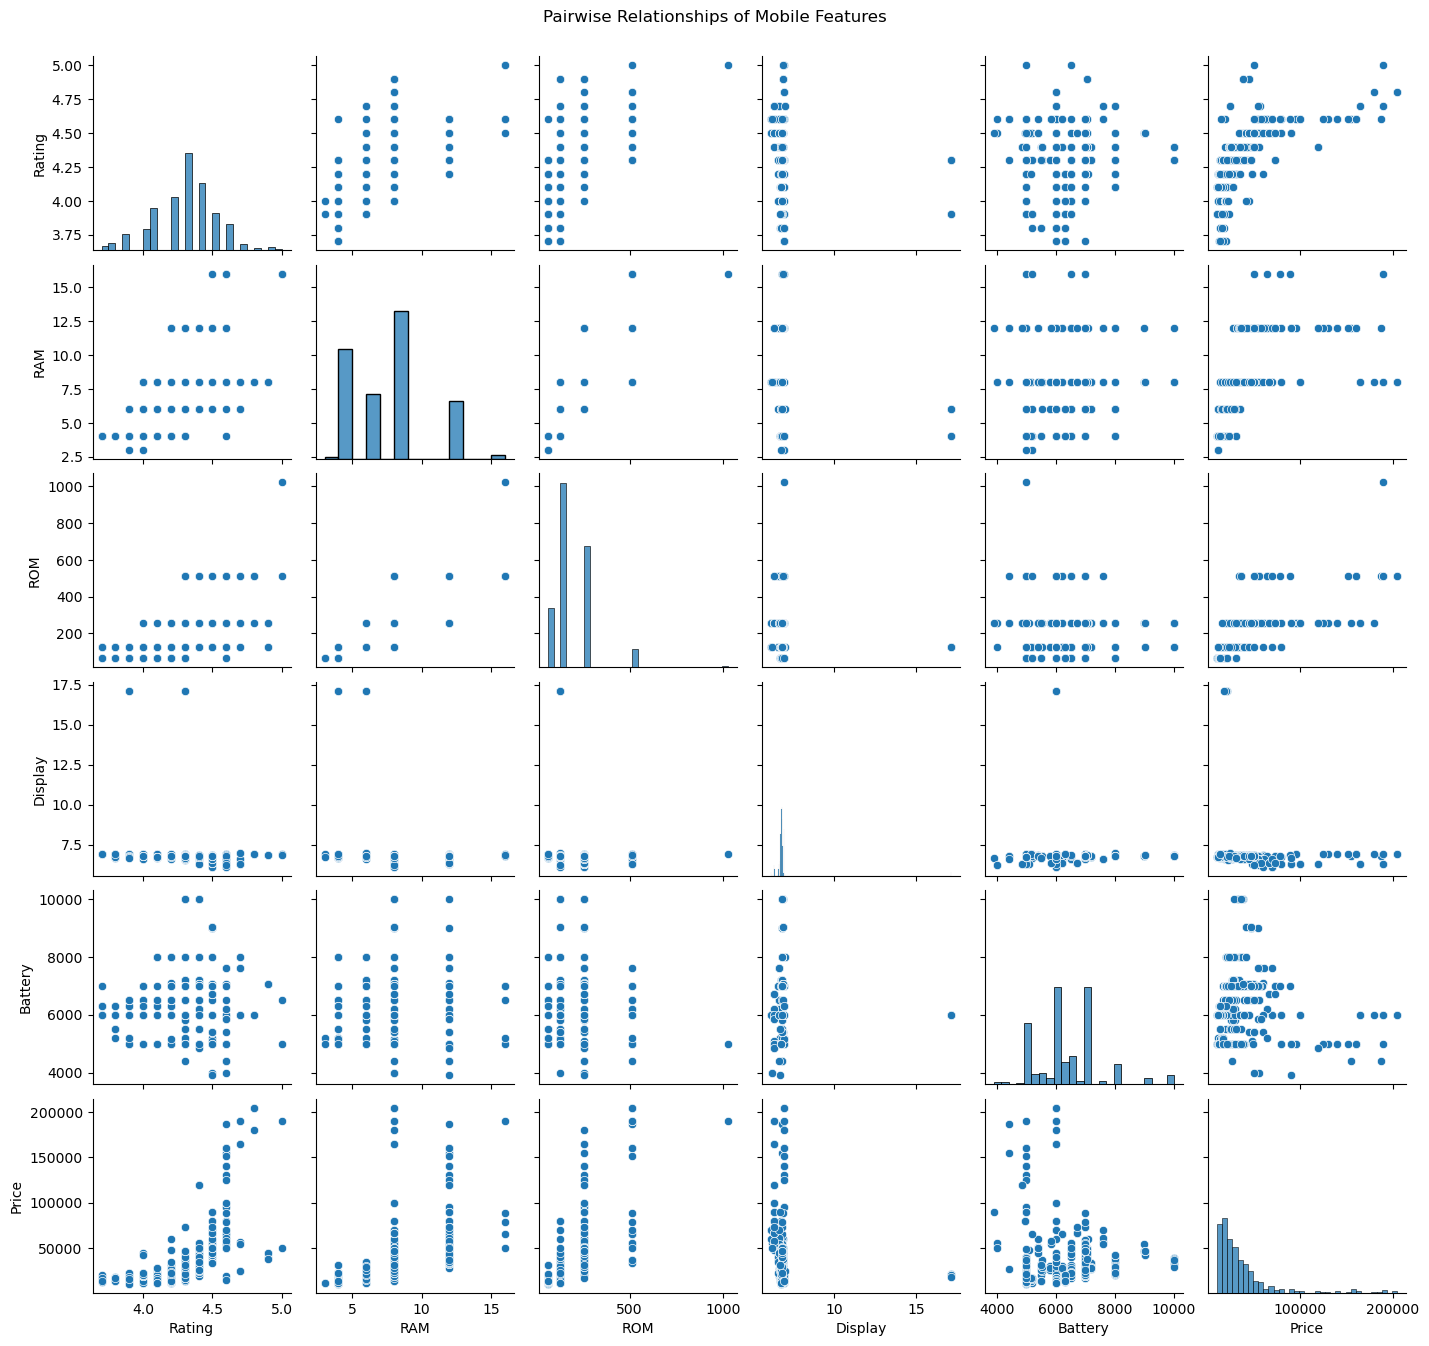

In [123]:
# Visualize pairwise relationships among numerical features
pair_plot = sns.pairplot(
    Mobiles_data[["Rating", "RAM", "ROM", "Display", "Battery", "Price"]],
    diag_kind="hist",
    height=2.2,
    aspect=1.1)

pair_plot.fig.suptitle(
    "Pairwise Relationships of Mobile Features",
    y=1.02)
plt.show()